# Tópicos com períodos do mesmo tamanho

Este caderno responde: **a mudança dos temas entre os períodos legais é real ou é efeito de os períodos terem tamanhos diferentes?**
Os períodos têm muito mais anúncios uns que outros, e o modelo de tópicos (LDA) aprende mais dos períodos grandes.
Aqui **sorteamos o mesmo número `n` de anúncios por período**, ajustamos o LDA, damos nome aos temas e repetimos 10 vezes
(sementes 0 a 9). Comparamos o resultado com o modelo atual (`t5`, corpus `corp3`).

Os números dos comentários foram lidos da saída da própria execução; se o banco mudar, **confira os números de novo**.

> **Cuidado ao ler:** os anúncios foram achados por **frases de busca**, não por sorteio, e os nomes dos temas são
> **hipóteses do grupo**. O sorteio aqui é só para igualar os períodos.

## Preparação: ler o corpus e o modelo atual

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from hdb import config
from hdb.banco import BancoSupabase
from hdb.topicos import equilibrado, nomear

pd.set_option("display.width", 200)
banco = BancoSupabase()
db = banco.cliente      # lê o config/.env pelo módulo hdb

def ler_tudo(consulta, bloco=1000):
    """Executa a consulta em blocos de 1000 linhas e junta o resultado."""
    linhas, inicio = [], 0
    while True:
        parte = consulta().range(inicio, inicio + bloco - 1).execute().data
        linhas += parte
        if len(parte) < bloco:
            return pd.DataFrame(linhas)
        inicio += bloco

PERIODOS = ["antes de 1831", "1831–1850", "1850–1871", "1871–1888"]
def periodo_curto(p):
    return p if p.startswith("antes") else p.split(" ")[0]

corpus = pd.DataFrame(banco.anuncios_do_corpus(config.VERSAO_CORPUS))
corpus = corpus[corpus["texto_padrao"].fillna("").str.strip() != ""]
corpus["periodo"] = corpus["periodo_legal"].map(lambda p: periodo_curto(p) if isinstance(p, str) else None)
corpus = corpus[corpus["periodo"].isin(PERIODOS)]
print(f"{len(corpus)} anúncios no corpus {config.VERSAO_CORPUS} com período legal")
if len(corpus) != 2167:
    print(f"ATENÇÃO: os comentários deste caderno foram escritos para 2167 anúncios e agora são {len(corpus)}: "
          "confira os números dos textos antes de usar.")

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

2167 anúncios no corpus corp3 com período legal


## 1. Quantos anúncios por período e qual `n`
`n` é o **tamanho do menor período grande** (entre os que têm pelo menos 200 anúncios). Cada sorteio pega `n` anúncios
de cada período. Quem tem menos de `n` (por exemplo, "antes de 1831") entra **inteiro** e fica **marcado**: o resultado
desse período é menos firme e ele pesa menos no modelo.

In [2]:
tamanho = corpus.groupby("periodo").size().reindex(PERIODOS, fill_value=0)
grandes = tamanho[tamanho >= 200]
N = int(grandes.min())
usado = tamanho.clip(upper=N)
aviso = ["" if t >= N else "ENTRA INTEIRO (menos de n)" for t in tamanho]
if N < 30:
    print(f"ATENÇÃO: n = {N} é menor que 30: o resultado é muito frágil.")
print(f"n = {N} (menor período com pelo menos 200 anúncios: {grandes.idxmin()})")
pd.DataFrame({"anúncios no corpus": tamanho, "usados por sorteio": usado, "aviso": aviso})

n = 365 (menor período com pelo menos 200 anúncios: 1871–1888)


,anúncios no corpus,usados por sorteio,aviso
periodo,,,
antes de 1831,152,152,ENTRA INTEIRO (menos de n)
1831–1850,565,365,
1850–1871,1085,365,
1871–1888,365,365,


**O que mostra:** o menor período com pelo menos 200 anúncios é 1871–1888 (365), então cada sorteio usa **365 anúncios** de 1831–1850, 1850–1871 e 1871–1888. Antes de 1831 só há 152 e eles entram **inteiros** (marcado com asterisco): é a coluna mais frágil.

## 2. O modelo atual
Os temas e as proporções médias por período do modelo já gravado no banco (sem equilíbrio). Os nomes vêm de
`hdb.topicos.nomear`, o mesmo critério do caderno de tópicos.

In [3]:
MODELO = config.VERSAO_TOPICOS
pal = ler_tudo(lambda: db.table("topico_palavras").select("topico,palavra,peso").eq("versao", MODELO)
               .order("topico").order("peso", desc=True))
dist = ler_tudo(lambda: db.table("anuncio_topicos").select("anuncio_id,topico,proporcao").eq("versao", MODELO)
                .order("anuncio_id").order("topico"))
K = pal["topico"].nunique()
NOMES = nomear({t: g.sort_values("peso", ascending=False)["palavra"].head(12) for t, g in pal.groupby("topico")})
pivo = dist.pivot(index="anuncio_id", columns="topico", values="proporcao")
atual = corpus.set_index("id")[["periodo"]].join(pivo, how="inner")
atual_media = atual.groupby("periodo")[list(pivo.columns)].mean().reindex(PERIODOS).T
atual_media.index = [NOMES[t] for t in atual_media.index]
print(f"modelo {MODELO}: {K} temas, {len(atual)} anúncios")
(atual_media * 100).round(1)

modelo t5: 6 temas, 2167 anúncios


periodo,antes de 1831,1831–1850,1850–1871,1871–1888
Venda com preço e qualidades,13.6,28.0,25.1,23.2
Ama de leite,21.3,16.8,19.7,17.2
Serviço doméstico (aluguel),9.4,18.1,26.8,26.7
Fuga: roupa levada e nação,11.3,11.1,11.8,16.0
Venda de moleques e pretos (lotes),10.5,13.6,8.5,10.7
"Fuga: nome, idade e dono",34.0,12.3,8.1,6.2


## 3. Os 10 sorteios com períodos do mesmo tamanho
Para cada sorteio, o LDA é ajustado do zero com **o mesmo número de temas do modelo atual**, os temas são nomeados e
medimos a proporção média de cada tema em cada período. Como os temas são nomeados por palavras de referência, um
tema pode **não aparecer** em algum sorteio (a média usa só os sorteios em que ele apareceu) e temas sem nome ficam de fora.

In [4]:
textos_por_periodo = {p: g["texto_padrao"].tolist() for p, g in corpus.groupby("periodo") if p in PERIODOS}
textos_por_periodo = {p: textos_por_periodo[p] for p in PERIODOS if p in textos_por_periodo}
r = equilibrado(textos_por_periodo, N, sorteios=10, n_topicos=K)
print("anúncios usados por período:", r["n_usado"])
print("períodos com menos de n (entraram inteiros):", r["curtos"])
print(f"temas sem nome nos 10 sorteios: {r['sem_nome']} (por sorteio: {r['sem_nome_por_sorteio']})")
n_aparece = {nome: sum(1 for s in r["sorteios"] if nome in s) for nome in r["media"]}
print("em quantos dos 10 sorteios cada tema apareceu:", n_aparece)

anúncios usados por período: {'antes de 1831': 152, '1831–1850': 365, '1850–1871': 365, '1871–1888': 365}
períodos com menos de n (entraram inteiros): ['antes de 1831']
temas sem nome nos 10 sorteios: 4 (por sorteio: [0, 0, 0, 0, 0, 1, 1, 1, 1, 0])
em quantos dos 10 sorteios cada tema apareceu: {'Ama de leite': 5, 'Fuga: nome, idade e dono': 8, 'Fuga: roupa levada e nação': 10, 'Serviço doméstico (aluguel)': 10, 'Venda com preço e qualidades': 10, 'Venda de moleques e pretos (lotes)': 4, 'Venda de mulheres (lavar, engomar, cozinhar)': 9}


## 4. Tabela: períodos iguais × modelo atual
Cada célula mostra a **proporção média (%)** do tema no período: primeiro a média dos sorteios com períodos iguais
(entre parênteses, o mínimo e o máximo dos sorteios), depois a do modelo atual. Uma diferença grande entre as duas
sugere que o tamanho do período estava mexendo no resultado. **Período marcado com `*` entrou inteiro (n menor que `n`).**

In [5]:
rot_p = {p: (p + " *" if p in r["curtos"] else p) for p in PERIODOS}
nomes_ord = list(r["media"])
linhas = []
for nome in nomes_ord:
    linha = {"Tema": nome}
    for p in PERIODOS:
        m, lo, hi = (100 * r[k][nome][p] for k in ("media", "minimo", "maximo"))
        a = 100 * atual_media.loc[nome, p] if nome in atual_media.index else float("nan")
        linha[rot_p[p]] = f"{m:.1f} ({lo:.1f}–{hi:.1f}) | atual {a:.1f}"
    linhas.append(linha)
pd.DataFrame(linhas).set_index("Tema")

,antes de 1831 *,1831–1850,1850–1871,1871–1888
Tema,,,,
Ama de leite,14.7 (9.3–18.5) | atual 21.3,14.7 (9.5–18.9) | atual 16.8,13.0 (10.2–17.6) | atual 19.7,11.3 (8.8–14.6) | atual 17.2
"Fuga: nome, idade e dono",15.5 (6.8–29.5) | atual 34.0,8.0 (5.6–9.9) | atual 12.3,7.7 (6.1–9.8) | atual 8.1,9.6 (5.6–12.1) | atual 6.2
Fuga: roupa levada e nação,29.9 (14.5–40.2) | atual 11.3,16.0 (9.7–21.4) | atual 11.1,12.7 (8.5–16.3) | atual 11.8,12.8 (7.5–18.9) | atual 16.0
Serviço doméstico (aluguel),13.5 (5.4–22.0) | atual 9.4,22.4 (12.0–38.6) | atual 18.1,28.0 (9.9–38.4) | atual 26.8,27.6 (9.2–38.2) | atual 26.7
Venda com preço e qualidades,11.7 (3.8–27.4) | atual 13.6,16.5 (5.8–37.0) | atual 28.0,16.2 (7.1–27.7) | atual 25.1,16.6 (8.6–22.4) | atual 23.2
Venda de moleques e pretos (lotes),12.3 (5.3–19.4) | atual 10.5,12.5 (8.4–16.7) | atual 13.6,8.4 (7.0–9.9) | atual 8.5,9.7 (5.8–15.4) | atual 10.7
"Venda de mulheres (lavar, engomar, cozinhar)",16.8 (9.7–28.5) | atual nan,20.9 (11.0–28.8) | atual nan,22.3 (13.6–32.6) | atual nan,20.9 (13.7–31.4) | atual nan


In [6]:
# Só as médias, em % (equilibrado, atual e diferença), para ler os números com mais facilidade
eq = pd.DataFrame(r["media"]).T.reindex(columns=PERIODOS) * 100
dif = (eq - (atual_media.reindex(eq.index) * 100)).round(1)
print("Período do mesmo tamanho (%):"); print(eq.round(1).to_string())
print("\nDiferença (equilibrado - atual), pontos percentuais:"); print(dif.to_string())

Período do mesmo tamanho (%):
                                              antes de 1831  1831–1850  1850–1871  1871–1888
Ama de leite                                           14.7       14.7       13.0       11.3
Fuga: nome, idade e dono                               15.5        8.0        7.7        9.6
Fuga: roupa levada e nação                             29.9       16.0       12.7       12.8
Serviço doméstico (aluguel)                            13.5       22.4       28.0       27.6
Venda com preço e qualidades                           11.7       16.5       16.2       16.6
Venda de moleques e pretos (lotes)                     12.3       12.5        8.4        9.7
Venda de mulheres (lavar, engomar, cozinhar)           16.8       20.9       22.3       20.9

Diferença (equilibrado - atual), pontos percentuais:
                                              antes de 1831  1831–1850  1850–1871  1871–1888
Ama de leite                                           -6.6       -2.2       -6

**O que se vê:** com períodos do mesmo tamanho, **a fuga somada** (os dois temas) fica em 45,4% antes de 1831, 24,0%, 20,4% e 22,4%, praticamente igual ao modelo principal (45,3%, 23,4%, 19,9% e 22,2%). O **serviço doméstico** sobe como no modelo principal: 13,5%, 22,4%, 28,0% e 27,6%. **Os outros temas não se mantêm:** ama de leite fica 6 a 7 pontos abaixo do modelo principal (de 14,7% a 11,3%, contra 21,3% a 17,2%) e venda com preço e qualidades fica 7 a 12 pontos abaixo depois de 1831.

## 5. Gráfico: o tema por período
Uma linha cheia é a **média dos sorteios** (a faixa vai do mínimo ao máximo); a linha tracejada é o **modelo atual**.
Se a linha cheia e a tracejada contam a mesma história, o tamanho do período não explica a mudança.

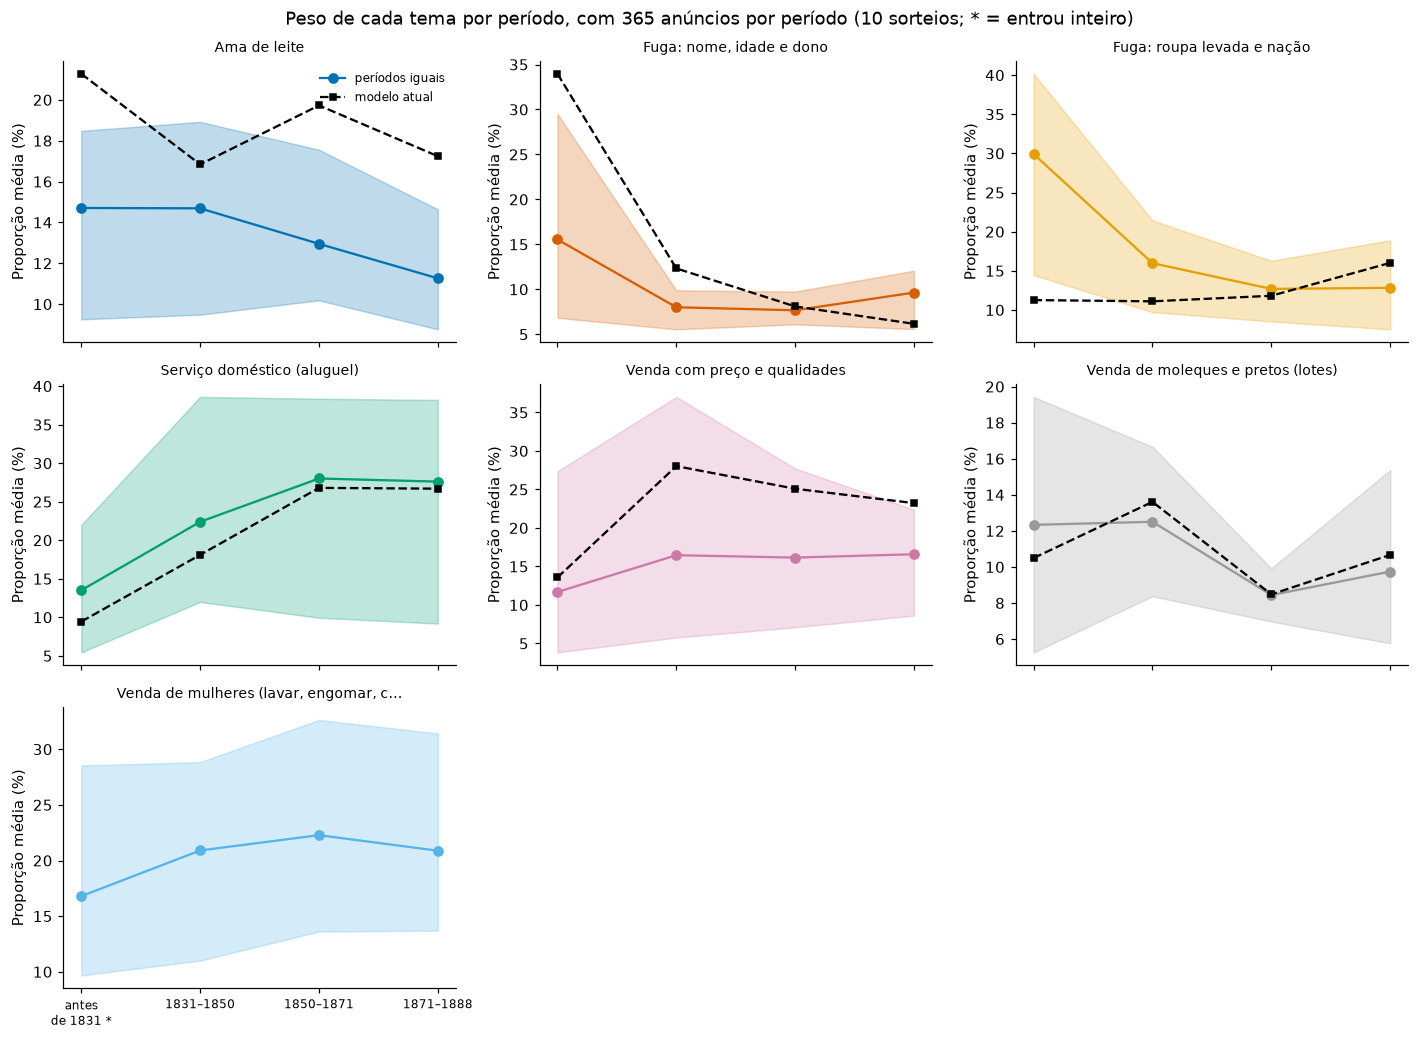

In [7]:
CORES = ["#0072B2", "#D55E00", "#E69F00", "#009E73", "#CC79A7", "#999999", "#56B4E9", "#F0E442"]
temas = list(r["media"])
colunas = 3
linhas_g = max(1, -(-len(temas) // colunas))
fig, eixos = plt.subplots(linhas_g, colunas, figsize=(13, 3.2 * linhas_g), sharex=True, squeeze=False)
x = np.arange(len(PERIODOS))
for i, nome in enumerate(temas):
    ax = eixos[i // colunas][i % colunas]
    cor = CORES[i % len(CORES)]
    m = np.array([r["media"][nome][p] for p in PERIODOS]) * 100
    lo = np.array([r["minimo"][nome][p] for p in PERIODOS]) * 100
    hi = np.array([r["maximo"][nome][p] for p in PERIODOS]) * 100
    ax.fill_between(x, lo, hi, color=cor, alpha=0.25)
    ax.plot(x, m, color=cor, marker="o", label="períodos iguais")
    if nome in atual_media.index:
        ax.plot(x, atual_media.loc[nome, PERIODOS].values * 100, color="black", ls="--", marker="s", ms=4, label="modelo atual")
    ax.set_title(nome if len(nome) < 38 else nome[:36] + "…", fontsize=9)
    ax.set_xticks(x); ax.set_xticklabels([rot_p[p].replace(" ", "\n", 1) if p.startswith("antes") else rot_p[p] for p in PERIODOS], fontsize=8)
    ax.set_ylabel("Proporção média (%)")
    if i == 0:
        ax.legend(frameon=False, fontsize=8)
for j in range(len(temas), linhas_g * colunas):
    eixos[j // colunas][j % colunas].set_axis_off()
fig.suptitle(f"Peso de cada tema por período, com {N} anúncios por período (10 sorteios; * = entrou inteiro)")
fig.tight_layout(); plt.show()

**O que o gráfico mostra:** as faixas entre os 10 sorteios são largas (muitas vezes de 8 a 20 pontos), então **diferenças menores que isso entre dois períodos não são evidência**. As linhas da fuga e do serviço doméstico se separam das faixas dos outros temas; as de ama de leite e de venda se sobrepõem entre os períodos.

## 6. O que isso diz e o que não diz

**O que sustenta:** a **queda da fuga** depois de 1831 e a **alta do serviço doméstico** resistem a períodos do mesmo tamanho. São os dois sinais mais fortes deste projeto, mas valem com as ressalvas dos demais cadernos (a mistura de tipos e a decisão sobre os aluguéis duvidosos).

**O que não sustenta:** ama de leite e venda, que mudam de tamanho conforme o corte. Dois temas de venda aparecem só em parte dos sorteios (o de moleques e pretos em 4 dos 10), o que mostra que **o modelo não é estável nesses temas**. Antes de 1831 há só 152 anúncios, então essa coluna varia muito (mais de 18 pontos na fuga de nome, idade e dono).